# RGB U-Net 기준 실험과 손실 함수 비교

- 작성자: kimjihwan
- 상태: **완료 — Colab 저장 출력 확인 (2026-11-24)**
- 작성일: 2026-11-24
- 관련 작업: T09 RGB U-Net 기본 실험
- [보고서](../../docs/rgb_unet/EXP_kimjihwan_002_rgb_unet_loss_compare.md) · 기준: [001 동작 확인](../../docs/rgb_unet/EXP_kimjihwan_001_unet_pipeline_check.md) · 참고: [전처리 실데이터 검증](../../docs/eda/EXP_byhyun_001_preprocessing_check.md)

## 목적

RGB 입력 ResNet-50 U-Net을 AutoSplice train 전체로 학습해 기준 성능을 얻음. 같은 조건에서 손실 함수만 바꾼 세 조건을 비교하고, val 조작 이미지 평균 F1로 이후 ELA·RGB+ELA U-Net에 쓸 손실을 고름.

| 조건 | 손실 |
| --- | --- |
| `bce` | BCEWithLogits |
| `dice` | 이미지별 soft Dice의 평균 |
| `bce_dice` | BCEWithLogits + 이미지별 soft Dice 평균 (1:1) |

## 001에서 바꾼 점

- 학습 데이터: train 조작 이미지 전체(2,925장, JPEG 100). 정상 이미지는 학습에서 제외함. 정상(Q75)·조작(Q100) 저장 이력 차이가 지름길이 되지 않도록 하기 위함이며, 조작 이미지의 마스크 밖 픽셀을 정상 예시로 사용함.
- 학습량: 최대 30 epoch, val 조작 평균 F1이 5 epoch 동안 오르지 않으면 조기 종료. 최고 val F1 체크포인트를 사용함.
- 평가 패딩: 팀 합의로 확정한 규약([전처리 안내](../../docs/preprocessing.md))에 따라 공통 함수 `pad_image`로 32의 배수 우하단 제로 패딩을 하고, 추론 후 `unpad_image`로 원본 크기로 되돌림. 001의 반사 패딩은 쓰지 않음.
- 테스트: [CAT-Net 004](https://github.com/hakeee0331/ai_forensics/pull/2)와 같은 범위·조건(AutoSplice test JPEG 100·90·75와 정상 원본, CocoGlide PNG→JPEG100·4:4:4). 손실 선택에는 test를 사용하지 않음.

T06 중 ELA 설정·전처리 순서·256 크롭·평가 패딩은 팀 합의로 확정됨. RGB 모델이라 ELA는 쓰지 않음. 손실·학습 조건·임계값·집계는 아직 미확정이며, 이 노트북의 해당 설정은 실행 기록임. 손실 비교 결과는 T06 학습 조건 논의의 근거로 사용함. 팀원이 VS Code의 Colab 원격 커널(A100)에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/`와 `AI_Forensics/project/scripts/`를 읽음. 체크포인트와 epoch별 기록은 공유 폴더 밖의 개인 폴더 `MyDrive/AI_Forensics_runs/kimjihwan/`에 저장함(T16 저장 구조 미정). 데이터·가중치는 Git에 올리지 않음.

In [1]:
from pathlib import Path
from google.colab import drive
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, features
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
experiment_name = "EXP_kimjihwan_002_rgb_unet_loss_compare"
run_root = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan") / experiment_name
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/evaluation.py",
            "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module
import scripts.evaluation as evaluation_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py"), (evaluation_module, "scripts/evaluation.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb, load_binary_mask, crop_pair, pad_image, unpad_image
from scripts.evaluation import confusion_counts, pixel_f1, iou, false_positive_rate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib", "torch", "torchvision"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("CUDA:", torch.version.cuda, "/ cuDNN:", torch.backends.cudnn.version())
print("TF32 matmul / cuDNN:", torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
print("CPU 코어:", os.cpu_count())
print("장치:", device)
if device.type != "cuda":
    raise RuntimeError("GPU 런타임(A100)에서 실행해야 함.")
properties = torch.cuda.get_device_properties(0)
print("GPU:", properties.name, f"{properties.total_memory / 1024**3:.1f} GiB")
print("실행 기록 폴더:", run_root)

Mounted at /content/drive
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
실행 시각 UTC: 2026-11-23T18:04:52.765072+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
JPEG library: 6.2
CUDA: 13.0 / cuDNN: 92800
TF32 matmul / cuDNN: False True
CPU 코어: 12
장치: cuda
GPU: NVIDIA L4 22.0 GiB
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_002_rgb_unet_loss_compare


In [2]:
# Git 저장소의 LF 줄바꿈 기준 해시임. Windows에서 CRLF로 바뀐 파일을 올리면 일치하지 않음.
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

seed = 42
config = dict(
    input_mode="rgb", mask_foreground=255, train_quality=100, train_kinds=["manipulated"],
    crop_size=256, crop_stride=16, flip_probability=0.5,
    encoder="torchvision resnet50", encoder_weights="IMAGENET1K_V2", normalization="ImageNet mean/std",
    optimizer="Adam", learning_rate=1e-4, batch_size=16, num_workers=2,
    max_epochs=30, patience=5, selection="val manipulated mean F1",
    dice_eps=1.0, threshold=0.5, pad_multiple=32, pad_mode="pad_image/unpad_image (bottom-right zero, pixel 0)",
    cocoglide_jpeg_quality=100, cocoglide_jpeg_subsampling=0, seed=seed,
)
conditions = ["bce", "dice", "bce_dice"]
config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
for key, value in config.items():
    print(f"{key}: {value}")
print("손실 조건:", conditions)
print("설정 해시:", config_hash)


def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)


set_seed(seed)
torch.backends.cudnn.benchmark = False

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
input_mode: rgb
mask_foreground: 255
train_quality: 100
train_kinds: ['manipulated']
crop_size: 256
crop_stride: 16
flip_probability: 0.5
encoder: torchvision resnet50
encoder_weights: IMAGENET1K_V2
normalization: ImageNet mean/std
optimizer: Adam
learning_rate: 0.0001
batch_size: 16
num_workers: 2
max_epochs: 30
patience: 5
selection: val manipulated mean F1
dice_eps: 1.0
threshold: 0.5
pad_multiple: 32
pad_mode: pad_image/unpad_image (bottom-right zero, pixel 0)
cocoglide_jpeg_quality: 100
cocoglide_jpeg_subsampling: 0
seed: 42
손실 조건: ['bce', 

## 2. 데이터 준비

두 ZIP을 해시 확인 후 해제함. 학습은 train 조작 이미지(JPEG 100), 검증은 val 조작 361장(F1·IoU)과 val 정상 227장(오탐률 기록)을 사용함.

테스트 목록은 004와 같게 구성함. AutoSplice test는 JPEG 100·90·75 조작본을 각각 평가하고 정상 원본은 한 번만 포함함. CocoGlide는 PNG를 RGB로 변환해 JPEG quality 100, subsampling 0으로 저장한 파일을 입력으로 사용하고, 정답 비교는 원본 크기의 마스크로 함.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])

records_by_quality = {q: autosplice_records(data_root / "AutoSplice", split_path, quality=q) for q in (100, 90, 75)}
base = records_by_quality[100]
train_records = [r for r in base if r["split"] == "train" and r["kind"] == "manipulated"]
val_records = [r for r in base if r["split"] == "val"]
for record in train_records + val_records:
    record["input_path"] = record["image_path"]

test_records = []
for quality, records in records_by_quality.items():
    for record in records:
        if record["split"] != "test" or (record["kind"] == "normal" and quality != 100):
            continue
        variant = "original" if record["kind"] == "normal" else f"JPEG{quality}"
        test_records.append(dict(record, variant=variant, input_path=record["image_path"], input_conversion="none"))

cocoglide_root = data_root / "CocoGlide"
jpeg_root = work_root / "unet_inputs" / "CocoGlide_JPEG100_444"
converted = 0
for record in cocoglide_records(cocoglide_root):
    source = record["image_path"]
    target = (jpeg_root / source.relative_to(cocoglide_root)).with_suffix(".jpg")
    target.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(source) as image:
        if image.format != "PNG":
            raise ValueError(f"CocoGlide 원본은 PNG여야 함: {source}")
        size = image.size
        image.convert("RGB").save(target, format="JPEG", quality=config["cocoglide_jpeg_quality"],
                                  subsampling=config["cocoglide_jpeg_subsampling"])
    with Image.open(target) as image:
        if image.format != "JPEG" or image.size != size:
            raise ValueError(f"변환 형식과 원본 크기가 일치해야 함: {target}")
    converted += 1
    test_records.append(dict(record, variant="PNG", input_path=target, input_conversion="PNG_to_JPEG100_444"))

if converted != 1024:
    raise ValueError("CocoGlide 변환 수는 1,024장이어야 함.")
if pd.Series([str(r["image_path"]) for r in test_records]).duplicated().any():
    raise ValueError("테스트 목록에 같은 이미지가 중복되지 않아야 함.")
assert {r["split"] for r in train_records} == {"train"} and {r["split"] for r in val_records} == {"val"}

print("학습 조작 이미지:", len(train_records))
display(pd.DataFrame(val_records).groupby("kind").size().rename("val images").to_frame())
test_table = pd.DataFrame(test_records)
display(test_table.groupby(["dataset", "split", "variant", "input_conversion", "kind"]).size().rename("images").reset_index())
print("테스트 이미지 합계:", len(test_records))

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료
학습 조작 이미지: 2925


,val images
kind,
manipulated,361
normal,227


,dataset,split,variant,input_conversion,kind,images
0,AutoSplice,test,JPEG100,none,manipulated,335
1,AutoSplice,test,JPEG75,none,manipulated,335
2,AutoSplice,test,JPEG90,none,manipulated,335
3,AutoSplice,test,original,none,normal,228
4,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512
5,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512


테스트 이미지 합계: 2257


## 3. 학습 입력 구성

이미지마다 매번 무작위 위치(16의 배수 좌표)에서 256×256을 자르고, 확률 0.5로 이미지와 마스크를 같이 좌우반전함. RGB 모델이라 ELA는 계산하지 않음. 무작위 값은 DataLoader 작업자마다 고정 시드에서 나오는 torch 난수를 사용함.

배치 입력 (16, 3, 256, 256) torch.float32 / 마스크 (16, 1, 256, 256) torch.float32 [0.0, 1.0]
epoch당 step: 182
배치 마스크 비율: [0.248, 0.566, 0.757, 0.827, 0.668, 0.555, 0.5, 0.815, 0.068, 0.786, 0.543, 0.773, 0.673, 0.283, 0.666, 0.071]


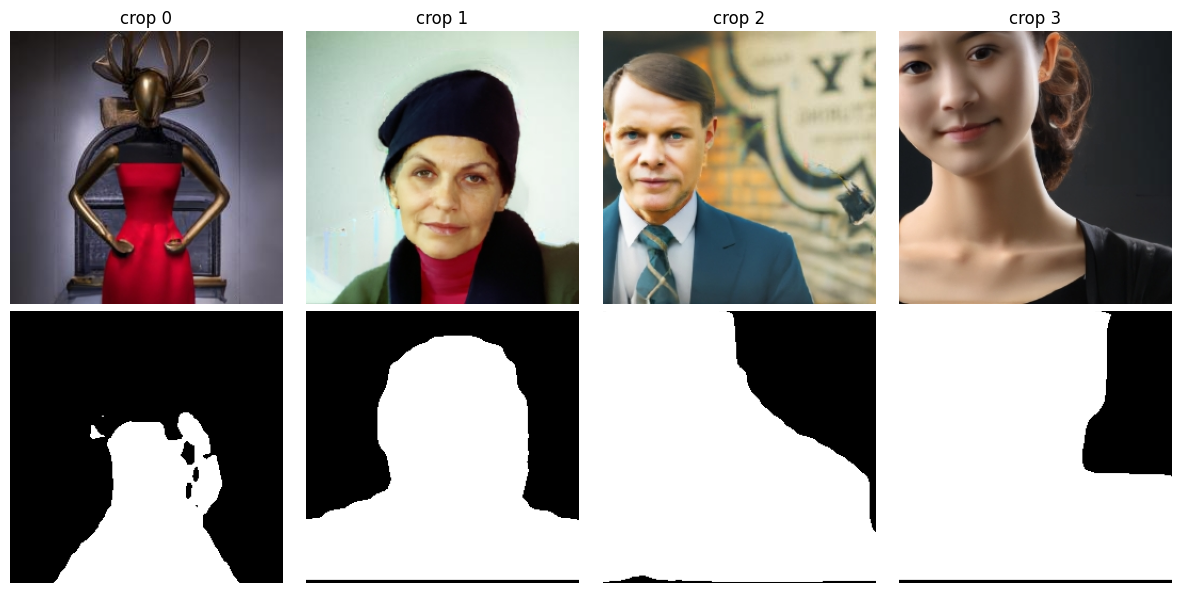

In [4]:
imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
imagenet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def load_pair(record):
    rgb = load_rgb(record["input_path"])
    if record["kind"] == "normal":
        mask = np.zeros(rgb.shape[:2], dtype=np.uint8)
    else:
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
    if rgb.shape[:2] != mask.shape:
        raise ValueError(f"이미지와 마스크 크기가 같아야 함: {record['input_path']}")
    return rgb, mask


def to_input(rgb):
    normalized = (rgb.astype(np.float32) / 255.0 - imagenet_mean) / imagenet_std
    return torch.from_numpy(normalized.transpose(2, 0, 1).copy())


class TrainCrops(torch.utils.data.Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rgb, mask = load_pair(self.records[index])
        size, stride = config["crop_size"], config["crop_stride"]
        top = int(torch.randint(0, (rgb.shape[0] - size) // stride + 1, ())) * stride
        left = int(torch.randint(0, (rgb.shape[1] - size) // stride + 1, ())) * stride
        rgb, mask = crop_pair(rgb, mask, top=top, left=left, height=size, width=size)
        if torch.rand(()) < config["flip_probability"]:
            rgb, mask = rgb[:, ::-1].copy(), mask[:, ::-1].copy()
        return to_input(rgb), torch.from_numpy(mask[None].astype(np.float32))


def make_train_loader(condition_seed):
    generator = torch.Generator().manual_seed(condition_seed)
    return torch.utils.data.DataLoader(TrainCrops(train_records), batch_size=config["batch_size"], shuffle=True,
                                       drop_last=True, num_workers=config["num_workers"], generator=generator,
                                       pin_memory=True, persistent_workers=config["num_workers"] > 0)


x, y = next(iter(make_train_loader(seed)))
print("배치 입력", tuple(x.shape), x.dtype, "/ 마스크", tuple(y.shape), y.dtype, torch.unique(y).tolist())
print("epoch당 step:", len(train_records) // config["batch_size"])
print("배치 마스크 비율:", [round(v, 3) for v in y.mean(dim=(1, 2, 3)).tolist()])

figure, axes = plt.subplots(2, 4, figsize=(12, 6))
for column in range(4):
    axes[0, column].imshow((x[column].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1))
    axes[1, column].imshow(y[column, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"crop {column}")
    for row in range(2):
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 4. 모델·손실·평가 함수

모델은 001과 같은 ResNet-50 U-Net임. 이후 ELA·RGB+ELA 실험에서도 같은 클래스를 쓰도록 입력 채널 인자를 유지함.

이미지별 Dice는 이미지마다 `1 − (2·Σpy + ε) / (Σp + Σy + ε)`를 구해 배치 평균함(ε=1). 크롭에 조작 영역이 없으면 예측이 0에 가까울수록 손실이 0에 가까워짐.

평가는 원본 크기 이미지를 `pad_image`로 우하단 제로 패딩해 추론하고 `unpad_image`로 원래 크기로 되돌린 뒤 임계값 0.5를 적용함. 정답 마스크는 패딩하지 않음. 조작 이미지는 F1·IoU, 정상 이미지는 픽셀 오탐률을 계산해 이미지별로 평균함(004와 같은 집계).

In [5]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.block(x)


class ResNet50UNet(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        if in_channels == 6:
            rgb_weight = encoder.conv1.weight.detach().clone()
            encoder.conv1 = nn.Conv2d(6, 64, 7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                encoder.conv1.weight.copy_(torch.cat([rgb_weight, rgb_weight], dim=1))
        elif in_channels != 3:
            raise ValueError("입력 채널은 3 또는 6이어야 함.")
        self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.pool = encoder.maxpool
        self.layers = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
        self.decoders = nn.ModuleList([
            DecoderBlock(2048, 1024, 256), DecoderBlock(256, 512, 128), DecoderBlock(128, 256, 64),
            DecoderBlock(64, 64, 32), DecoderBlock(32, 0, 16),
        ])
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        if x.shape[-2] % 32 or x.shape[-1] % 32:
            raise ValueError("입력 높이·너비는 32의 배수여야 함.")
        stem = self.stem(x)
        features = []
        out = self.pool(stem)
        for layer in self.layers:
            out = layer(out)
            features.append(out)
        out = features[-1]
        for decoder, skip in zip(self.decoders, [features[2], features[1], features[0], stem, None]):
            out = decoder(out, skip)
        return self.head(out)


def dice_per_image(logits, target, eps):
    probability = torch.sigmoid(logits)
    intersection = (probability * target).sum(dim=(1, 2, 3))
    total = probability.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * intersection + eps) / (total + eps)).mean()


def compute_loss(condition, logits, target):
    if condition == "bce":
        return F.binary_cross_entropy_with_logits(logits, target)
    if condition == "dice":
        return dice_per_image(logits, target, config["dice_eps"])
    if condition == "bce_dice":
        return F.binary_cross_entropy_with_logits(logits, target) + dice_per_image(logits, target, config["dice_eps"])
    raise ValueError(f"알 수 없는 손실 조건: {condition}")


def predict_full(model, rgb):
    padded, original_size = pad_image(rgb, multiple=config["pad_multiple"])
    with torch.no_grad():
        logits = model(to_input(padded)[None].to(device, non_blocking=True))
    probability = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
    return unpad_image(probability, original_size=original_size)


def evaluate(model, records, keep=None):
    model.eval()
    rows, kept = [], {}
    for record in records:
        rgb, mask = load_pair(record)
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, tn = confusion_counts(mask, prediction)
        row = {k: record.get(k) for k in ("dataset", "split", "variant", "input_conversion", "kind", "original_id")}
        row.update(image=Path(record["image_path"]).name, height=mask.shape[0], width=mask.shape[1],
                   tp=tp, fp=fp, fn=fn, tn=tn, f1=None, iou=None, fpr=None)
        if record["kind"] == "manipulated":
            row.update(f1=pixel_f1(tp, fp, fn), iou=iou(tp, fp, fn))
        else:
            row.update(fpr=false_positive_rate(fp, tn))
        rows.append(row)
        if keep is not None and row["image"] in keep:
            kept[row["image"]] = (rgb, mask, probability)
    frame = pd.DataFrame(rows)
    for column in ("f1", "iou", "fpr"):
        frame[column] = pd.to_numeric(frame[column])
    return (frame, kept) if keep is not None else frame


model = ResNet50UNet(3).to(device)
with torch.no_grad():
    for shape in [(2, 3, 256, 256), (1, 3, 256, 384)]:
        assert model(torch.randn(shape, device=device)).shape == (shape[0], 1, shape[2], shape[3])
probe = torch.zeros(2, 1, 64, 64)
probe[0, :, :32] = 1
assert dice_per_image(torch.full_like(probe, -20.0), probe, 1.0).item() > 0.4
assert dice_per_image(torch.where(probe > 0, 20.0, -20.0), probe, 1.0).item() < 1e-3
print("파라미터 수:", sum(p.numel() for p in model.parameters()))
print("출력 크기·이미지별 Dice 계산 확인")
del model

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 235MB/s]


파라미터 수: 32520977
출력 크기·이미지별 Dice 계산 확인


## 5. 세 손실 조건 학습

조건마다 같은 시드(42)로 모델·데이터 순서·크롭 난수를 초기화하므로 손실 외의 조건이 같음. 매 epoch 끝에 val 전체를 원본 크기로 평가하고, val 조작 평균 F1이 최고일 때만 체크포인트를 Drive에 저장함. 5 epoch 연속 개선이 없으면 종료함.

학습을 마친 조건은 Drive에 `done.json`을 남김. 커널이 끊겨 다시 실행하면 같은 설정 해시의 완료 조건은 건너뜀. 학습 중 끊긴 조건은 처음부터 다시 학습함. 설정이 다른 기록이 있으면 덮어쓰지 않고 중단함.

In [6]:
run_root.mkdir(parents=True, exist_ok=True)
all_history = []

for condition in conditions:
    condition_dir = run_root / condition
    condition_dir.mkdir(parents=True, exist_ok=True)
    done_path, best_path = condition_dir / "done.json", condition_dir / "best.pt"
    if done_path.is_file():
        done = json.loads(done_path.read_text())
        if done["config_hash"] != config_hash:
            raise ValueError(f"{condition}: 다른 설정의 기록이 있음. 폴더를 확인해야 함: {condition_dir}")
        history = pd.read_csv(condition_dir / "history.csv")
        all_history.append(history)
        print(f"[{condition}] 완료 기록 사용: best epoch {done['best_epoch']}, val F1 {done['best_val_f1']:.4f}")
        continue

    set_seed(seed)
    model = ResNet50UNet(3).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    loader = make_train_loader(seed)
    torch.cuda.reset_peak_memory_stats()
    best_f1, best_epoch, stale, rows = -1.0, 0, 0, []
    print(f"[{condition}] 학습 시작")
    for epoch in range(1, config["max_epochs"] + 1):
        model.train()
        start = time.perf_counter()
        losses = []
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = compute_loss(condition, model(x), y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"{condition} epoch {epoch}: 손실이 유한해야 함.")
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        train_seconds = time.perf_counter() - start

        start = time.perf_counter()
        val = evaluate(model, val_records)
        val_seconds = time.perf_counter() - start
        manipulated, normal = val[val.kind == "manipulated"], val[val.kind == "normal"]
        row = dict(condition=condition, epoch=epoch, train_loss=float(np.mean(losses)),
                   val_f1=manipulated.f1.mean(), val_iou=manipulated.iou.mean(), val_normal_fpr=normal.fpr.mean(),
                   train_seconds=train_seconds, val_seconds=val_seconds)
        improved = row["val_f1"] > best_f1
        if improved:
            best_f1, best_epoch, stale = row["val_f1"], epoch, 0
            torch.save({"condition": condition, "epoch": epoch, "config": config, "config_hash": config_hash,
                        "state_dict": model.state_dict()}, best_path)
        else:
            stale += 1
        row["best"] = improved
        rows.append(row)
        print(f"[{condition}] epoch {epoch:2d} loss {row['train_loss']:.4f} | val F1 {row['val_f1']:.4f} "
              f"IoU {row['val_iou']:.4f} normal FPR {row['val_normal_fpr']:.4f} | "
              f"train {train_seconds:.0f}s val {val_seconds:.0f}s{' *' if improved else ''}")
        if stale >= config["patience"]:
            print(f"[{condition}] {config['patience']} epoch 동안 개선 없음. 조기 종료")
            break

    history = pd.DataFrame(rows)
    history.to_csv(condition_dir / "history.csv", index=False)
    done = dict(condition=condition, config_hash=config_hash, best_epoch=best_epoch, best_val_f1=best_f1,
                epochs_run=len(rows), peak_gpu_gib=torch.cuda.max_memory_allocated() / 1024**3,
                finished_utc=datetime.now(timezone.utc).isoformat())
    done_path.write_text(json.dumps(done, indent=1))
    all_history.append(history)
    print(f"[{condition}] 종료: best epoch {best_epoch}, val F1 {best_f1:.4f}, 최대 GPU 메모리 {done['peak_gpu_gib']:.1f} GiB")
    del model, optimizer, loader
    torch.cuda.empty_cache()

history = pd.concat(all_history, ignore_index=True)

[bce] 학습 시작
[bce] epoch  1 loss 0.3958 | val F1 0.9198 IoU 0.8668 normal FPR 0.0031 | train 30s val 12s *
[bce] epoch  2 loss 0.2972 | val F1 0.9323 IoU 0.8794 normal FPR 0.0060 | train 29s val 12s *
[bce] epoch  3 loss 0.2515 | val F1 0.9431 IoU 0.9006 normal FPR 0.0028 | train 29s val 12s *
[bce] epoch  4 loss 0.2176 | val F1 0.9439 IoU 0.9027 normal FPR 0.0020 | train 30s val 12s *
[bce] epoch  5 loss 0.1872 | val F1 0.9512 IoU 0.9129 normal FPR 0.0004 | train 30s val 12s *
[bce] epoch  6 loss 0.1633 | val F1 0.9546 IoU 0.9172 normal FPR 0.0035 | train 30s val 12s *
[bce] epoch  7 loss 0.1429 | val F1 0.9553 IoU 0.9178 normal FPR 0.0025 | train 30s val 12s *
[bce] epoch  8 loss 0.1281 | val F1 0.9392 IoU 0.8947 normal FPR 0.0016 | train 30s val 12s
[bce] epoch  9 loss 0.1137 | val F1 0.9573 IoU 0.9214 normal FPR 0.0015 | train 30s val 12s *
[bce] epoch 10 loss 0.1012 | val F1 0.9547 IoU 0.9200 normal FPR 0.0033 | train 30s val 12s
[bce] epoch 11 loss 0.0914 | val F1 0.9592 IoU 0.924

/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1921377760.py:10: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()

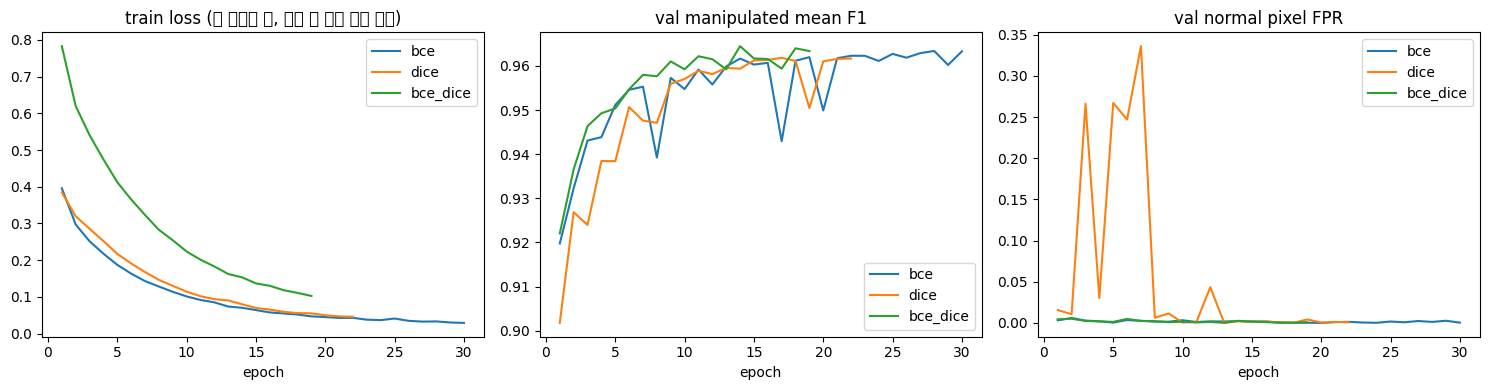

,condition,epochs_run,best_epoch,val_f1,val_iou,val_normal_fpr,peak_gpu_gib,minutes
0,bce,30,28,0.963386,0.931693,0.001249,3.247983,21.085985
1,dice,22,17,0.961830,0.929687,0.000930,3.250302,15.489755
2,bce_dice,19,14,0.964472,0.933288,0.002561,3.247006,13.364777


val 조작 평균 F1 기준 선택 손실: bce_dice


In [7]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for condition, group in history.groupby("condition", sort=False):
    axes[0].plot(group.epoch, group.train_loss, label=condition)
    axes[1].plot(group.epoch, group.val_f1, label=condition)
    axes[2].plot(group.epoch, group.val_normal_fpr, label=condition)
for axis, title in zip(axes, ["train loss (각 손실의 값, 조건 간 직접 비교 불가)", "val manipulated mean F1", "val normal pixel FPR"]):
    axis.set_title(title)
    axis.set_xlabel("epoch")
    axis.legend()
plt.tight_layout()
plt.show()

selection = []
for condition in conditions:
    done = json.loads((run_root / condition / "done.json").read_text())
    best = history[(history.condition == condition) & (history.epoch == done["best_epoch"])].iloc[0]
    selection.append(dict(condition=condition, epochs_run=done["epochs_run"], best_epoch=done["best_epoch"],
                          val_f1=best.val_f1, val_iou=best.val_iou, val_normal_fpr=best.val_normal_fpr,
                          peak_gpu_gib=done["peak_gpu_gib"],
                          minutes=(history[history.condition == condition][["train_seconds", "val_seconds"]].sum().sum()) / 60))
selection = pd.DataFrame(selection)
with pd.option_context("display.float_format", "{:.6f}".format):
    display(selection)
selected = selection.sort_values("val_f1", ascending=False).iloc[0].condition
print("val 조작 평균 F1 기준 선택 손실:", selected)

## 6. 테스트 평가

세 조건 모두 최고 val 체크포인트로 test를 평가함. 손실 선택은 위 val 결과로 이미 정했으며 test 결과로 바꾸지 않음. 결과는 004와 같은 묶음(데이터셋·분할·변형·입력 변환·종류)으로 이미지별 점수를 평균함. 이미지별 결과는 Drive의 조건 폴더에 `test_rows.csv`로 저장함.

In [8]:
vis_rng = np.random.default_rng(seed)
vis_names = []
for dataset, kind in [("AutoSplice", "manipulated"), ("AutoSplice", "manipulated"), ("AutoSplice", "normal"),
                      ("CocoGlide", "manipulated"), ("CocoGlide", "normal")]:
    candidates = [r for r in test_records if r["dataset"] == dataset and r["kind"] == kind
                  and r.get("variant") in ("JPEG100", "original", "PNG") and Path(r["image_path"]).name not in vis_names]
    vis_names.append(Path(candidates[int(vis_rng.integers(len(candidates)))]["image_path"]).name)

test_summaries, kept_by_condition = [], {}
group_columns = ["dataset", "split", "variant", "input_conversion", "kind"]
for condition in conditions:
    checkpoint = torch.load(run_root / condition / "best.pt", map_location=device)
    if checkpoint["config_hash"] != config_hash:
        raise ValueError(f"{condition}: 체크포인트 설정 해시가 현재 설정과 같아야 함.")
    model = ResNet50UNet(3).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    start = time.perf_counter()
    rows, kept_by_condition[condition] = evaluate(model, test_records, keep=set(vis_names))
    seconds = time.perf_counter() - start
    rows.to_csv(run_root / condition / "test_rows.csv", index=False)
    summary = rows.groupby(group_columns).agg(images=("image", "size"), pixel_f1=("f1", "mean"), iou=("iou", "mean"),
                                              normal_pixel_fpr=("fpr", "mean")).reset_index()
    summary.insert(0, "condition", condition)
    test_summaries.append(summary)
    print(f"[{condition}] best epoch {checkpoint['epoch']}, test {len(rows)}장 평가 {seconds:.0f}s")
    del model

test_summary = pd.concat(test_summaries, ignore_index=True)
with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", None, "display.width", 200):
    display(test_summary)
    pivot = test_summary.assign(score=test_summary.pixel_f1.fillna(test_summary.normal_pixel_fpr),
                                metric=np.where(test_summary.kind == "manipulated", "F1", "normal FPR"))
    display(pivot.pivot_table(index=["dataset", "variant", "metric"], columns="condition", values="score", sort=False)[conditions])

[bce] best epoch 28, test 2257장 평가 31s
[dice] best epoch 17, test 2257장 평가 32s
[bce_dice] best epoch 14, test 2257장 평가 32s


,condition,dataset,split,variant,input_conversion,kind,images,pixel_f1,iou,normal_pixel_fpr
0,bce,AutoSplice,test,JPEG100,none,manipulated,335,0.968074,0.939608,NaN
1,bce,AutoSplice,test,JPEG75,none,manipulated,335,0.006794,0.004126,NaN
2,bce,AutoSplice,test,JPEG90,none,manipulated,335,0.275670,0.184482,NaN
3,bce,AutoSplice,test,original,none,normal,228,NaN,NaN,0.000497
4,bce,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512,0.359908,0.257431,NaN
5,bce,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512,NaN,NaN,0.978932
6,dice,AutoSplice,test,JPEG100,none,manipulated,335,0.968277,0.940300,NaN
7,dice,AutoSplice,test,JPEG75,none,manipulated,335,0.006654,0.003543,NaN
8,dice,AutoSplice,test,JPEG90,none,manipulated,335,0.177471,0.114593,NaN
9,dice,AutoSplice,test,original,none,normal,228,NaN,NaN,0.000682


condition                           bce     dice  bce_dice
dataset    variant  metric                                
AutoSplice JPEG100  F1         0.968074 0.968277  0.968899
           JPEG75   F1         0.006794 0.006654  0.005337
           JPEG90   F1         0.275670 0.177471  0.278731
           original normal FPR 0.000497 0.000682  0.000570
CocoGlide  PNG      F1         0.359908 0.360594  0.360052
                    normal FPR 0.978932 0.970703  0.970198

## 7. 예측 시각화

test에서 고정 시드로 고른 AutoSplice 조작 2장·정상 1장, CocoGlide 조작 1장·정상 1장의 세 조건 예측 확률을 비교함. 정성 확인용이며 표본 선택은 점수를 보기 전에 정함.

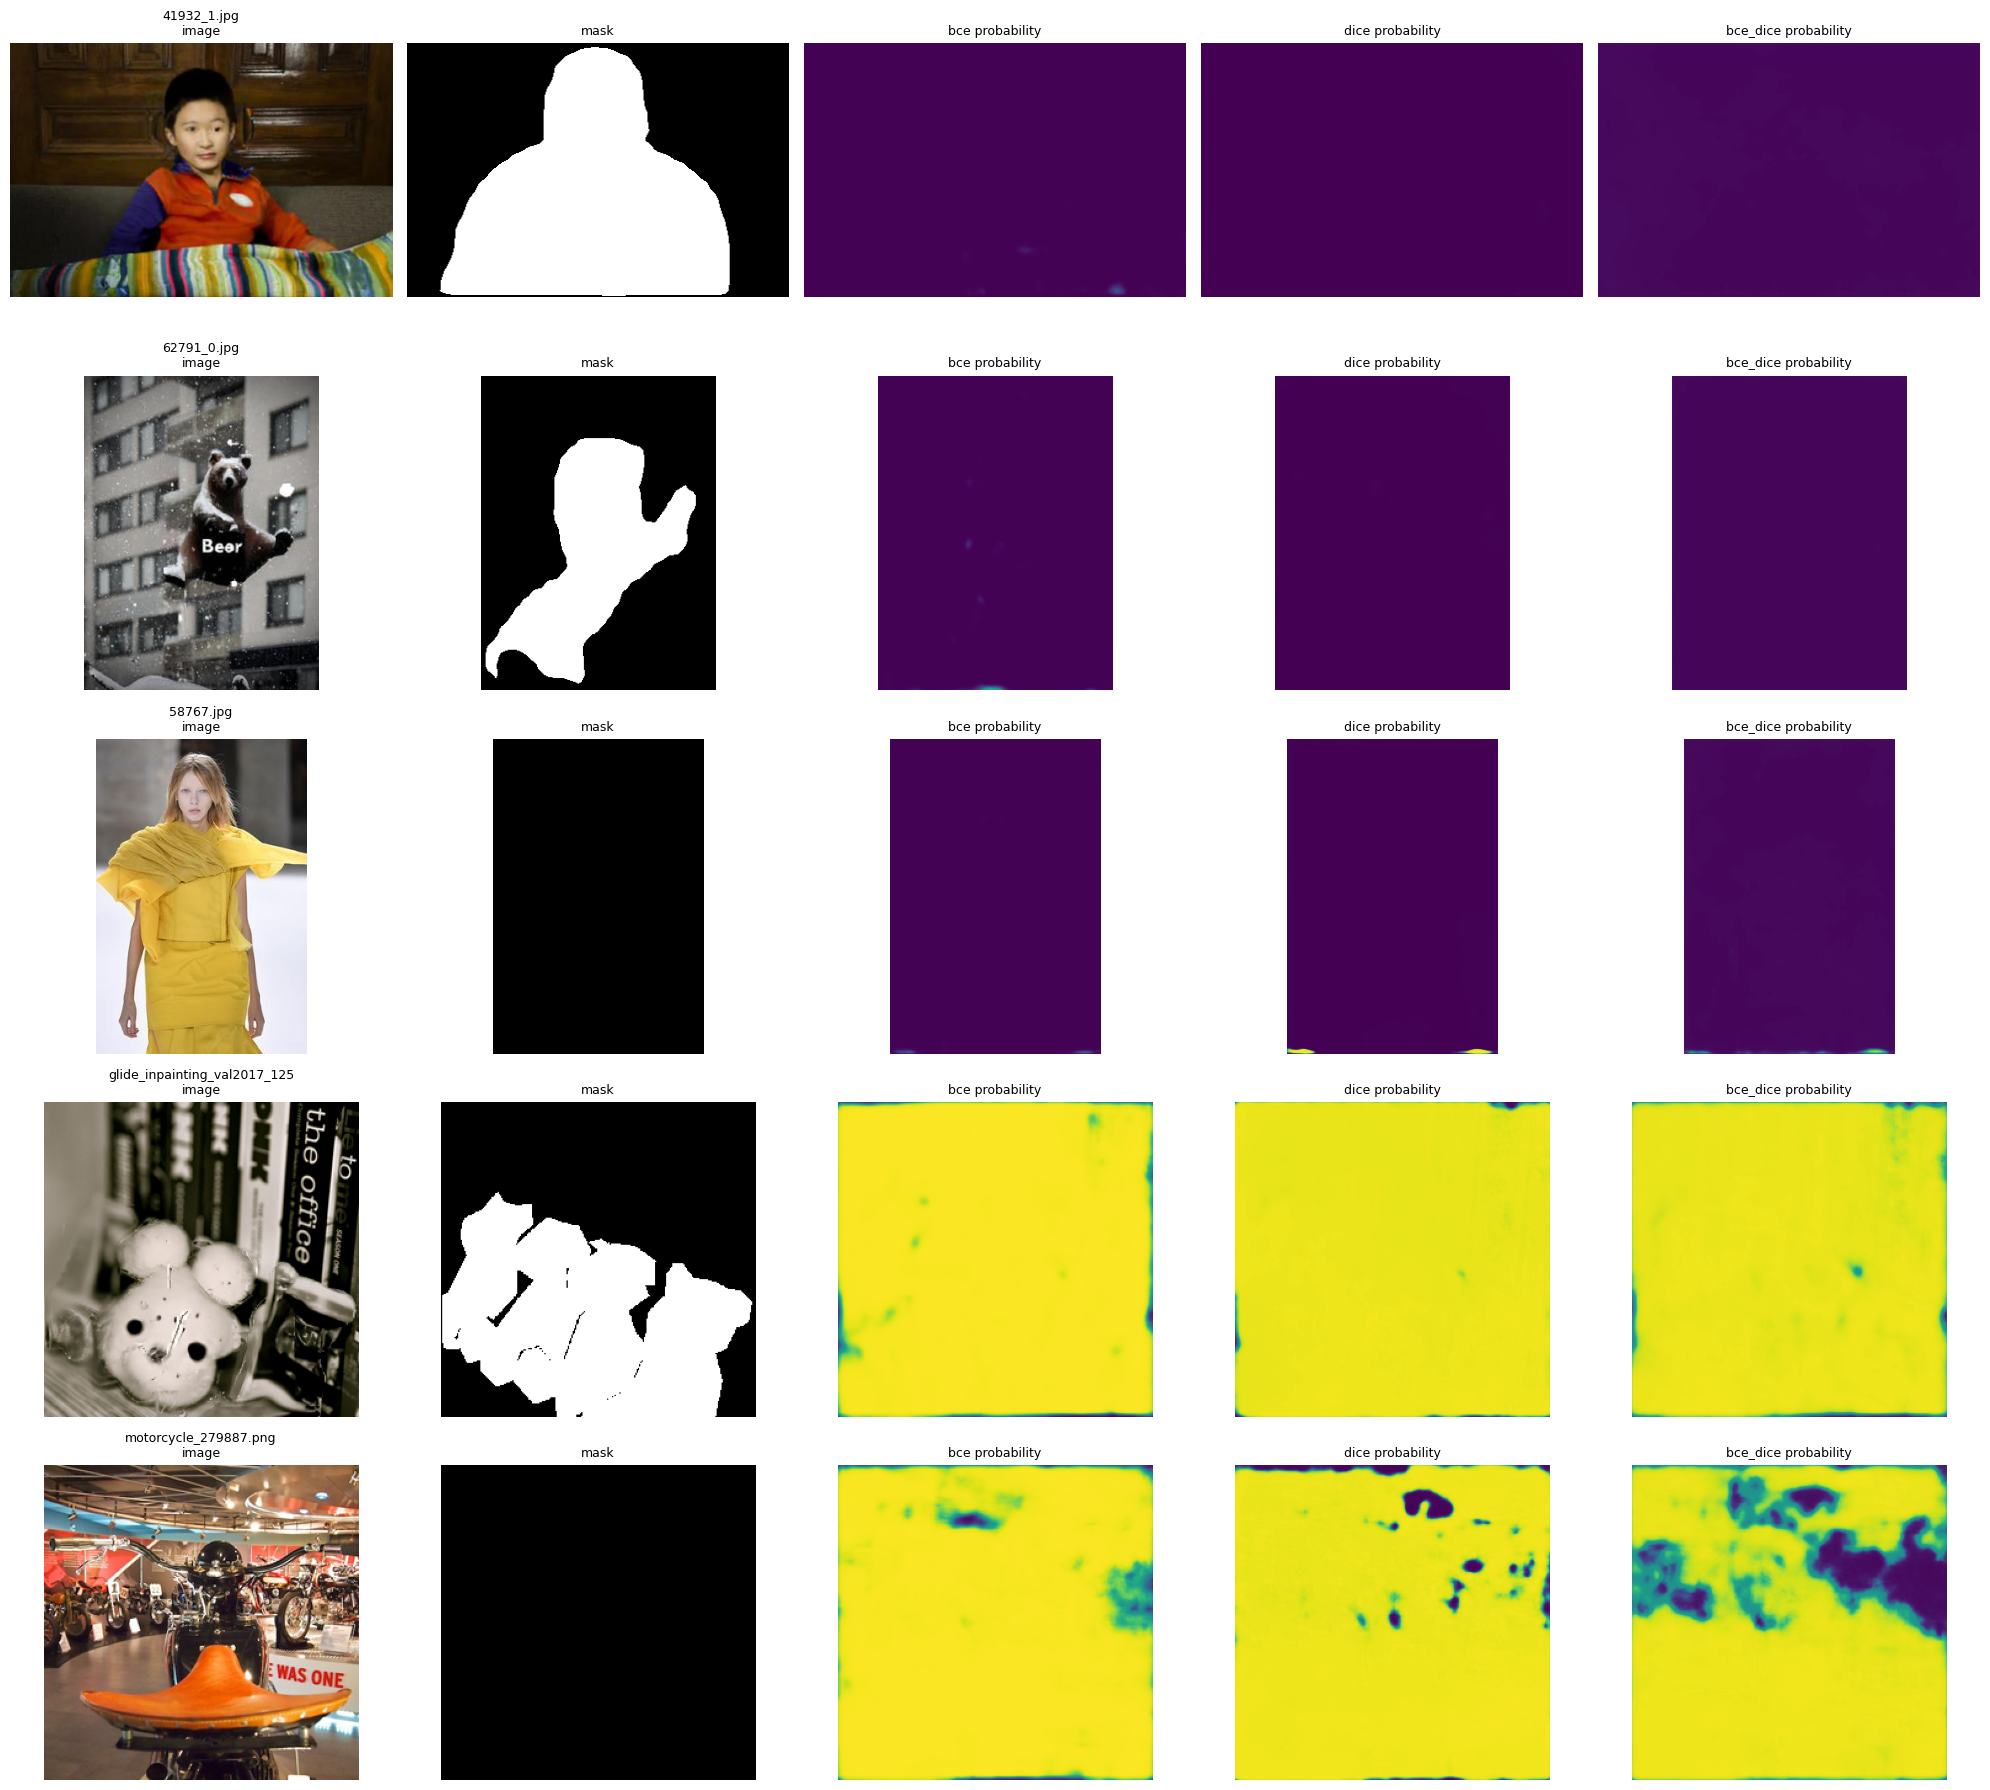

In [9]:
figure, axes = plt.subplots(len(vis_names), 2 + len(conditions), figsize=(4 * (2 + len(conditions)), 3.6 * len(vis_names)))
for row, name in enumerate(vis_names):
    rgb, mask, _ = kept_by_condition[conditions[0]][name]
    panels = [(rgb, "image", None), (mask, "mask", "gray")]
    for condition in conditions:
        panels.append((kept_by_condition[condition][name][2], f"{condition} probability", "viridis"))
    for column, (image, title, cmap) in enumerate(panels):
        axes[row, column].imshow(image, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        axes[row, column].set_title(f"{name[:28]}\n{title}" if column == 0 else title, fontsize=9)
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 8. 확인 결과와 검토 메모

아래 셀은 실행 범위를 요약함. 해석과 성공·실패 사례 분석은 보고서에 작성함.

사람 검토 메모(실행 후 작성):

- 3절 학습 크롭 그림의 이미지·마스크 대응:
- 5절 학습 곡선(과적합·조기 종료 시점):
- 7절 예측 그림의 성공·실패 사례:
- 특이사항(실행 시간, 끊김·재실행 여부 등):

In [10]:
print("설정 해시:", config_hash)
print("실행 기록 폴더:", run_root)
for condition in conditions:
    done = json.loads((run_root / condition / "done.json").read_text())
    print(f"{condition}: epoch {done['epochs_run']}회 학습, best epoch {done['best_epoch']}, val F1 {done['best_val_f1']:.6f}")
print("선택 손실(val 기준):", selected)
print("테스트 평가 행 수:", len(test_summary))
print("실험 완료. 손실 선택은 val 조작 평균 F1로만 정함")

설정 해시: 4a4acbe4d60c
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_002_rgb_unet_loss_compare
bce: epoch 30회 학습, best epoch 28, val F1 0.963386
dice: epoch 22회 학습, best epoch 17, val F1 0.961830
bce_dice: epoch 19회 학습, best epoch 14, val F1 0.964472
선택 손실(val 기준): bce_dice
테스트 평가 행 수: 18
실험 완료. 손실 선택은 val 조작 평균 F1로만 정함
